# Capítulo 3 · Métodos basados en políticas

**Lectura:** pp. 51–82; §§3.1–3.6. [Capítulo original](https://arxiv.org/html/2412.05265v5#Ch3).

**Idea central:** ajustar directamente la distribución de acciones permite optimizar políticas estocásticas y manejar acciones continuas, pero exige controlar la varianza y el tamaño de las actualizaciones.

## Resumen

En §3.1 se deriva el gradiente mediante la identidad de la derivada logarítmica. No hace falta diferenciar la dinámica: basta muestrear trayectorias y conocer la probabilidad de las acciones elegidas. REINFORCE aumenta la probabilidad de acciones asociadas a mejores retornos. Usar recompensa futura en vez del retorno completo evita atribuir a una acción recompensas que ocurrieron antes.

Restar un baseline que no dependa de la acción, tratado como constante en el estimador, conserva la esperanza del gradiente. Un baseline adecuado puede reducir mucho su varianza. El valor del estado es una elección habitual; no cualquier baseline reduce la varianza.

En §3.2, actor-critic combina una política con un estimador de valor. El crítico permite usar bootstrap para actualizar sin esperar al episodio completo. A2C usa un error TD como estimación de ventaja. GAE mezcla errores TD a distintos horizontes mediante $\lambda$, intercambiando sesgo y varianza. La calidad del crítico y la coordinación de las dos tasas de aprendizaje importan.

El gradiente natural tiene en cuenta cómo los cambios de parámetros modifican distribuciones, usando la geometría de Fisher. Para acciones continuas, DDPG entrena un actor determinista guiado por un crítico. TD3 combate errores y sobreestimación mediante dos críticos, actualizaciones retardadas y suavizado del objetivo. WPO explora otra geometría para mover distribuciones de acciones.

En §3.3, TRPO y PPO buscan limitar cambios destructivos. TRPO aproxima una actualización restringida por KL. PPO usa un objetivo recortado más sencillo y permite varias actualizaciones sobre un lote. El clipping limita incentivos en ese objetivo; no impone por sí solo una cota dura a toda la divergencia ni garantiza mejora en cada ejecución. VMPO ofrece una alternativa basada en distribución auxiliar y proyección.

§3.4 explica cómo reutilizar datos de otra política. El muestreo por importancia corrige el cambio de distribución cuando hay soporte suficiente, pero sus productos pueden tener mucha varianza. V-trace y Retrace introducen correcciones y truncamientos. IMPALA combina estos principios con recogida distribuida. Off-policy no significa automáticamente que un conjunto fijo y arbitrario de datos sea suficiente.

§3.5 recuerda que también existen búsqueda aleatoria, estrategias evolutivas y otros métodos sin gradientes. Finalmente, §3.6 interpreta control como inferencia: favorecer trayectorias de alta recompensa conduce a objetivos con entropía o KL. MPO, AWR/AWAC y SAC se entienden desde esa perspectiva. SAC aprende una política estocástica con un objetivo de recompensa más entropía. La discusión de inferencia activa conecta percepción, preferencias y búsqueda de información.

## Ecuaciones esenciales

Para episodios sin descuento, una forma de REINFORCE es

$$
\nabla_\theta J=
\mathbb{E}\left[\sum_t
\nabla_\theta\log\pi_\theta(a_t|s_t)(G_t-b(s_t))\right].
$$

Si $J=\mathbb{E}[\sum_t\gamma^t r_t]$ y $G_t$ descuenta desde $t$, la forma por trayectoria incluye además un factor $\gamma^t$. Otras presentaciones lo incorporan a la distribución de visitas. En el laboratorio hay un solo paso y no surge esta distinción.

$$
\delta_t=r_t+\gamma V(s_{t+1})-V(s_t),
\qquad
\hat A_t^{\mathrm{GAE}}=\sum_{l\geq0}(\gamma\lambda)^l\delta_{t+l}.
$$

La suma se trunca y los valores terminales se tratan adecuadamente en episodios finitos.

## Experimento 3 · ¿Qué aporta un baseline?

Un bandit contextual tiene dos contextos equiprobables y tres acciones. Las medias, sin un desplazamiento común, son $(1,0,-1)$ y $(-1,0,1)$. Añadimos 5 a todas las recompensas y ruido normal con desviación 0.5.

Se entrenan dos políticas softmax con REINFORCE: una sin baseline y otra con una media móvil por contexto, calculada con lotes anteriores. Usamos 500 actualizaciones, lotes de 32 y 20 semillas.

~~~bash
uv run python -m experimentos.ejecutar --capitulo 3
~~~

**Control importante:** además del aprendizaje, medimos ambos estimadores bajo una misma política uniforme fija, con 50.000 muestras y baseline exacto 5. Comparar varianzas de políticas distintas no aislaría el efecto del baseline.

**Métricas:** recompensa esperada exacta menos el desplazamiento 5; y traza de la covarianza del gradiente en el control fijo.

**Resultado observado:** la varianza cae aproximadamente de 17.07 a 0.392. Ambas políticas alcanzan recompensas finales parecidas, alrededor de 0.967 frente al óptimo 1. Reducir varianza no implica necesariamente obtener una media final superior con este presupuesto.

**Modificación:** elimina el desplazamiento 5 y repite. Luego usa deliberadamente un baseline muy inadecuado. Razona por qué conservar la esperanza no garantiza reducir la varianza.

**Límite:** ilustra REINFORCE y baselines; no implementa PPO, GAE ni un crítico neuronal.



## Para el grupo

1. ¿Por qué un baseline dependiente de la acción necesita tratamiento adicional?
2. ¿Qué diferencia hay entre menos varianza y menos sesgo?
3. ¿Qué permite afirmar el clipping de PPO y qué habría que medir aparte?

**Conexión:** las ideas de gradiente, ventaja y KL reaparecen en el ajuste de LLM del capítulo 6.


## Preparar la ejecución

Ejecuta todas las celdas en orden. El módulo contiene la implementación completa; la siguiente celda muestra su código. Cambia SEMILLA y REPLICAS para repetir. Los resultados del cuaderno se guardan en una carpeta separada.

In [1]:
from pathlib import Path
import sys
import json
import inspect
import subprocess
import importlib
from IPython.display import display, Image, Code

candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next(p for p in candidates if (p / "experimentos" / "ejecutar.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
CAPITULO = 3
SEMILLA = 2026
REPLICAS = 20
SALIDA = ROOT / "resultados" / "cuadernos"
modulo = importlib.import_module(f"experimentos.cap{CAPITULO:02d}")
display(Code(inspect.getsource(modulo), language="python"))

"""Cap. 3: REINFORCE y reducción de varianza mediante un baseline."""
import numpy as np
import matplotlib.pyplot as plt
from .comun import softmax, curva, guardar, filas_finales, resumen_muestra

MEDIAS = np.array([[1., 0., -1.], [-1., 0., 1.]])

def entrenar(seed, baseline, pasos=500, batch=32):
    rng = np.random.default_rng(seed)
    theta = np.zeros((2, 3))
    b = np.zeros(2)
    valores = [0.]
    for _ in range(pasos):
        s = rng.integers(0, 2, batch)
        probs = softmax(theta)
        a = (rng.random(batch)[:, None] > np.cumsum(probs[s], axis=1)).sum(axis=1)
        rewards = 5 + MEDIAS[s, a] + rng.normal(0, .5, batch)
        advantage = rewards - b[s] if baseline else rewards
        score = np.eye(3)[a] - probs[s]
        grad = np.zeros_like(theta)
        np.add.at(grad, s, advantage[:, None]*score / batch)
        theta += .1*grad
        # El baseline de ESTE lote se calculó antes de observar sus recompensas.
        for context in range(2):
            if np.any(s == context):
                b[context] = .9*b[context]+.1*rewards[s == context].mean()
        valores.append(float((softmax(theta)*MEDIAS).sum()/2))
    return np.array(valores)

def ejecutar(out, seed=2026, replicas=20):
    runs = {label: np.array([entrenar(seed+k, use) for k in range(replicas)])
            for label, use in [("Sin baseline", False), ("Baseline aprendido", True)]}
    # Medimos la varianza con la misma política fija, no durante políticas distintas.
    rng = np.random.default_rng(seed+100000)
    a = rng.integers(0, 3, 50000)
    r = 5 + MEDIAS[0, a] + rng.normal(0, .5, len(a))
    score = np.eye(3)[a] - 1/3
    g0, gb = r[:, None]*score, (r-5)[:, None]*score
    variances = np.array([g0.var(axis=0, ddof=1).sum(), gb.var(axis=0, ddof=1).sum()])
    exact = MEDIAS[0]/3
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    for name, values in runs.items():
        curva(ax[0], np.arange(values.shape[1])*32, values, name)
    ax[0].axhline(1, color="black", ls="--", label="Óptimo")
    ax[0].set(xlabel="Interacciones", ylabel="Recompensa esperada menos 5", title="Aprendizaje de la política")
    ax[0].legend()
    ax[1].bar(["Sin baseline", "Baseline exacto 5"], variances)
    ax[1].set(ylabel="Traza de covarianza del gradiente", title="Varianza con política uniforme fija")
    metrics = {"batch": 32, "iteraciones": 500, "learning_rate": .1,
               "final": {n: resumen_muestra(v[:, -1]) for n, v in runs.items()},
               "varianza_sin_baseline": float(variances[0]), "varianza_con_baseline": float(variances[1]),
               "gradiente_exacto_contexto_0": exact.tolist(),
               "gradiente_estimado_sin_baseline": g0.mean(axis=0).tolist(),
               "gradiente_estimado_con_baseline": gb.mean(axis=0).tolist()}
    rows = [row for n, v in runs.items() for row in filas_finales(n, v[:, -1])]
    return guardar(out, {**runs, "varianzas": variances}, rows, metrics, fig)

## Ejecutar y registrar

El comando utiliza el mismo Python del kernel y conserva parámetros y hashes en su manifiesto. No necesita servicios externos.

In [2]:
command = [sys.executable, "-m", "experimentos.ejecutar",
           "--capitulo", str(CAPITULO), "--semilla", str(SEMILLA),
           "--replicas", str(REPLICAS), "--salida", str(SALIDA)]
completed = subprocess.run(command, cwd=ROOT, capture_output=True, text=True, check=True)
print(completed.stdout)
carpeta = SALIDA / f"cap{CAPITULO:02d}"

Capítulo 3: completado en 0.79 s → /home/ialab/jairo_experiments/kevinMurphy/resultados/cuadernos/cap03



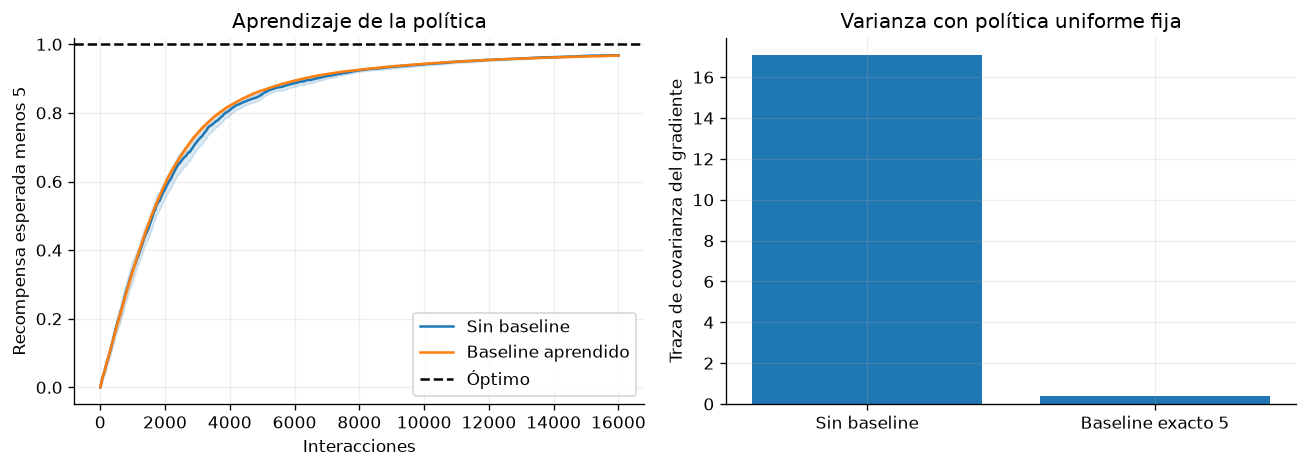

{
  "batch": 32,
  "iteraciones": 500,
  "learning_rate": 0.1,
  "final": {
    "Sin baseline": {
      "media": 0.9679913650826064,
      "ic95_aprox_semianchura": 0.0018422861936547802
    },
    "Baseline aprendido": {
      "media": 0.9672748888416635,
      "ic95_aprox_semianchura": 0.0006263486087180437
    }
  },
  "varianza_sin_baseline": 17.06691789600838,
  "varianza_con_baseline": 0.39157332619612534,
  "gradiente_exacto_contexto_0": [
    0.3333333333333333,
    0.0,
    -0.3333333333333333
  ],
  "gradiente_estimado_sin_baseline": [
    0.35297557808325863,
    -0.01918650568097333,
    -0.3337890724022832
  ],
  "gradiente_estimado_con_baseline": [
    0.33764224474992394,
    -0.0022198390143067983,
    -0.3354224057356183
  ]
}


In [3]:
display(Image(filename=str(carpeta / "figura.png")))
resumen = json.loads((carpeta / "resumen.json").read_text())
print(json.dumps(resumen, indent=2, ensure_ascii=False))

## Inspeccionar los datos

Las claves describen métricas; las dimensiones suelen ser réplica × instante, excepto los arrays auxiliares. Escribe una conclusión que apoyen los datos y una limitación. Prueba la modificación propuesta en el texto; antes de ejecutarla, predice su efecto.

In [4]:
import numpy as np
with np.load(carpeta / "datos.npz") as datos:
    for nombre in datos.files:
        print(nombre, datos[nombre].shape)

Sin baseline (20, 501)
Baseline aprendido (20, 501)
varianzas (2,)


## Tu variante

Anota aquí: hipótesis, parámetro cambiado, métrica, resultado y limitación. Para modificar la dinámica o el algoritmo, edita el módulo mostrado o copia su función a una celda y experimenta con ella.

Fuente: [Kevin P. Murphy, Reinforcement Learning: An Overview, v5](https://arxiv.org/abs/2412.05265v5), [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). Resumen adaptado y experimento propio de esta guía.